# Telco Customer Churn Analysis and Prediction System

## Bhone Min Khant (SE)
## Ykpt-22522

## 1. **DATA OVERVIEW**

**Importing libriaries & Upload**

In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Telco_Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. **Data Understanding**

In [104]:
print("Data Shape =", df.shape)

Data Shape = (7043, 21)


In [105]:
print("Column names\n")
df.columns.tolist()

Column names



['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [106]:
print("Data types\n")
display(df.dtypes.to_frame("dtype"))


Data types



,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


`TotalCharges` dtypes should be Numeric.

### Check Null and Duplicate

**Duplicate Check**

In [107]:
df.duplicated().sum()

np.int64(0)

**Null value Check**

In [108]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


## 3. **Data Preprocessing**


### 3.1 TotalCharges Cleaning

In [109]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [110]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [111]:
print("Check NaN in total charge:\n")
df.loc[
    df["TotalCharges"].isnull(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

Check NaN in total charge:



,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Found NaN in Tenure=0 , it must be new customer

In [112]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df["TotalCharges"].isnull().sum()

np.int64(0)

### 3.2 Target Distribution

In [113]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [114]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


Customer 7,043

Churn  1,869

Churn Rate 26.54%

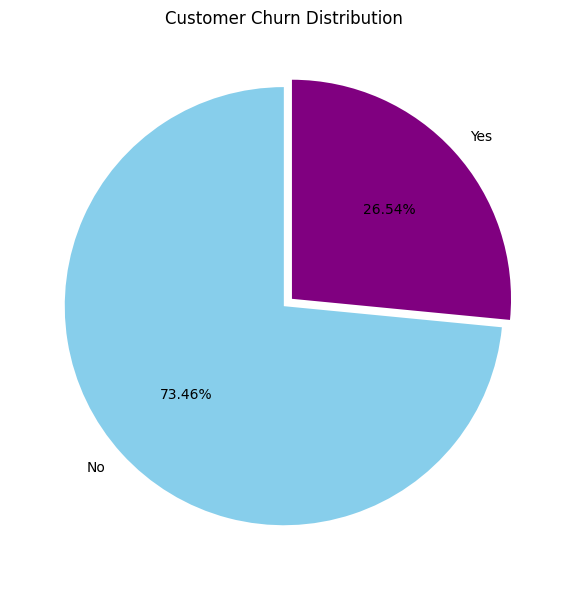

In [115]:
import matplotlib.pyplot as plt

churn_counts = df["Churn"].value_counts()

colors = ['skyblue', 'purple']

plt.figure(figsize=(6, 6))
plt.pie(
    churn_counts.values,
    labels=churn_counts.index,
    autopct='%1.2f%%',
    startangle=90,
    colors=colors,
    explode=(0, 0.05),
    shadow=False
)
plt.title("Customer Churn Distribution")
plt.tight_layout()
plt.show()

In [116]:
df["ChurnFlag"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

df[["Churn", "ChurnFlag"]].head()

,Churn,ChurnFlag
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1


## 4. Descriptive Mining

### 4.1Churn by Contract

In [117]:
def churn_by_group(df, column):
    result = df.groupby(column)["ChurnFlag"].agg(["mean", "count"])
    result["churn_rate_pct"] = result["mean"] * 100

    return result.drop(columns="mean").sort_values(
        "churn_rate_pct",
        ascending=False
    )

In [118]:
contract_churn = churn_by_group(df, "Contract")

display(contract_churn)

,count,churn_rate_pct
Contract,,
Month-to-month,3875,42.709677
One year,1473,11.269518
Two year,1695,2.831858


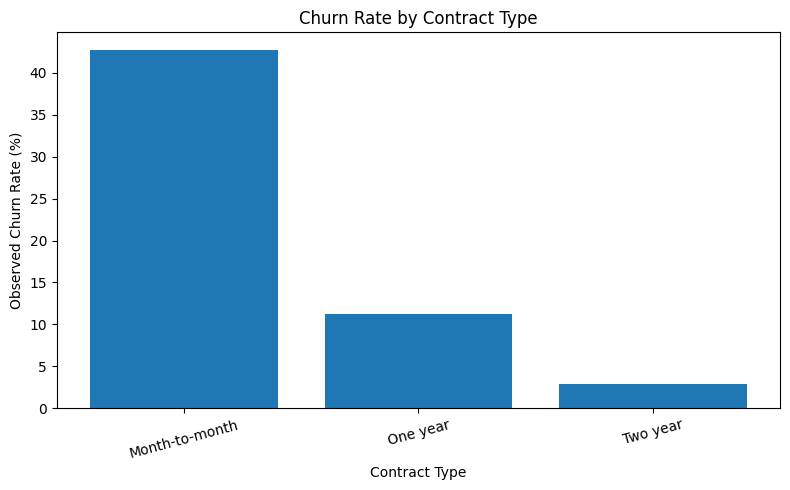

In [119]:
plt.figure(figsize=(8, 5))

plt.bar(
    contract_churn.index,
    contract_churn["churn_rate_pct"]
)

plt.xlabel("Contract Type")
plt.ylabel("Observed Churn Rate (%)")
plt.title("Churn Rate by Contract Type")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

Month-to-month customers show a higher observed churn rate compared with customers on longer-term contracts

### 4.2 Churn by TechSupport

In [120]:
techsupport_churn = churn_by_group(df, "TechSupport")

display(techsupport_churn)

,count,churn_rate_pct
TechSupport,,
No,3473,41.635474
Yes,2044,15.166341
No internet service,1526,7.404980


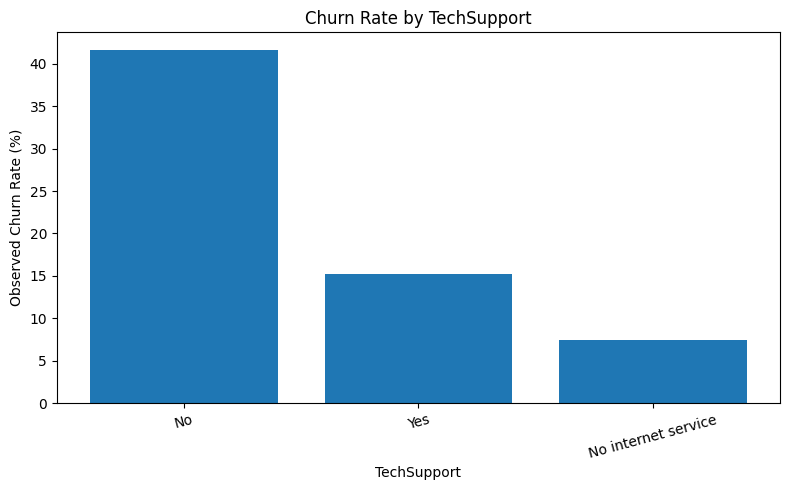

In [121]:
plt.figure(figsize=(8, 5))

plt.bar(
    techsupport_churn.index,
    techsupport_churn["churn_rate_pct"]
)

plt.xlabel("TechSupport")
plt.ylabel("Observed Churn Rate (%)")
plt.title("Churn Rate by TechSupport")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Customers without TechSupport have a higher observed churn rate

### 4.3 Churn by Internet Service

In [122]:
internet_churn = churn_by_group(df, "InternetService")

display(internet_churn)

,count,churn_rate_pct
InternetService,,
Fiber optic,3096,41.892765
DSL,2421,18.959108
No,1526,7.404980


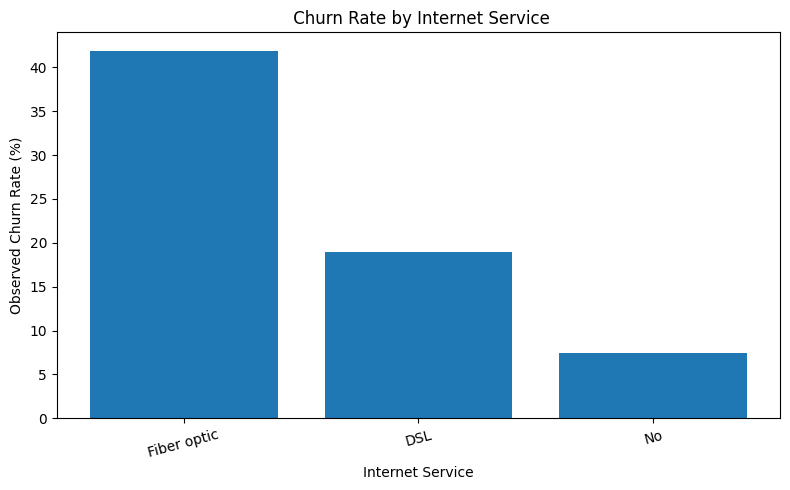

In [123]:
plt.figure(figsize=(8, 5))

plt.bar(
    internet_churn.index,
    internet_churn["churn_rate_pct"]
)

plt.xlabel("Internet Service")
plt.ylabel("Observed Churn Rate (%)")
plt.title(" Churn Rate by Internet Service")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Fiber optic customers have a higher observed churn rate compared with DSL and customers without internet service

### 4.4 Churn by Payment

In [124]:
payment_churn = churn_by_group(df, "PaymentMethod")

display(payment_churn)

,count,churn_rate_pct
PaymentMethod,,
Electronic check,2365,45.285412
Mailed check,1612,19.106700
Bank transfer (automatic),1544,16.709845
Credit card (automatic),1522,15.243101


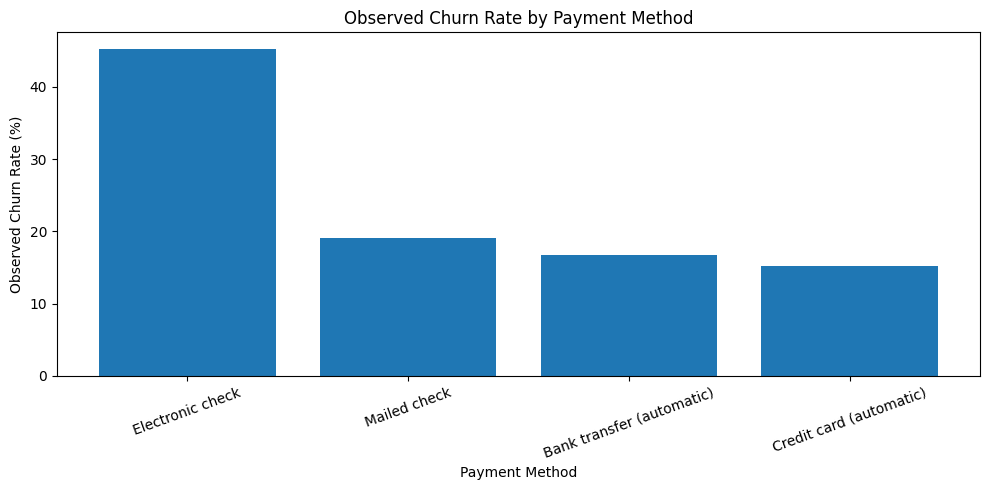

In [125]:
plt.figure(figsize=(10, 5))

plt.bar(
    payment_churn.index,
    payment_churn["churn_rate_pct"]
)

plt.xlabel("Payment Method")
plt.ylabel("Observed Churn Rate (%)")
plt.title("Observed Churn Rate by Payment Method")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

###  4.5 Churn by Tenure

In [126]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
     labels=["0-6", "7-12", "13-24", "25-48", "49-72"]
)

tenure_churn = churn_by_group(df,"tenure_group")

display(tenure_churn)

/tmp/ipykernel_2549/3732677220.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  result = df.groupby(column)["ChurnFlag"].agg(["mean", "count"])


,count,churn_rate_pct
tenure_group,,
0-6,1481,52.937205
7-12,705,35.886525
13-24,1024,28.710938
25-48,1594,20.388959
49-72,2239,9.513176


### 4.6 Churn by Monthly Charges  

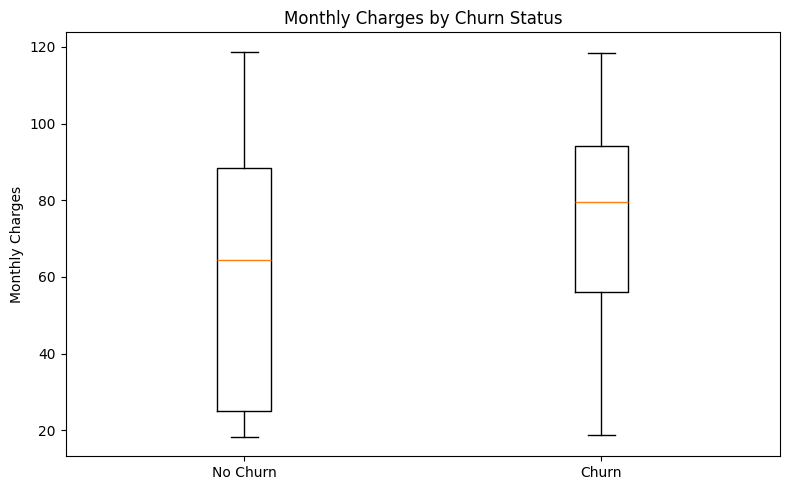

In [127]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df.loc[df["Churn"] == "No", "MonthlyCharges"],
        df.loc[df["Churn"] == "Yes", "MonthlyCharges"]
    ],
    labels=["No Churn", "Churn"]
)

plt.ylabel("Monthly Charges")
plt.title("Monthly Charges by Churn Status")

plt.tight_layout()
plt.show()

### 4.7 Demographic

In [128]:
for col in [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PaperlessBilling"
]:

    print("\n==============================")
    print(col)
    print("==============================")

    display(churn_by_group(df, col))


gender


,count,churn_rate_pct
gender,,
Female,3488,26.920872
Male,3555,26.160338



SeniorCitizen


,count,churn_rate_pct
SeniorCitizen,,
1,1142,41.681261
0,5901,23.606168



Partner


,count,churn_rate_pct
Partner,,
No,3641,32.957979
Yes,3402,19.664903



Dependents


,count,churn_rate_pct
Dependents,,
No,4933,31.279140
Yes,2110,15.450237



PaperlessBilling


,count,churn_rate_pct
PaperlessBilling,,
Yes,4171,33.565092
No,2872,16.330084


In Gender male and female are too close.(no big difference)

Senior citizens have a higher observed churn rate than non-senior customers.

No Partner and Dependents observed high churn rate

Yes Paperlessbilling have high churn rate

### **Summary**
Churn appears to be more common among newer customers, month-to-month contract customers, customers without TechSupport, fiber-optic customers, and electronic-check users

## 5. **ASSOCIATION MINING**


### 5.1 Association Mining

In [129]:
import pandas as pd
import numpy as np

assoc_df = df.copy()

assoc_df["SeniorCitizen"] = assoc_df["SeniorCitizen"].map({
    0: "SeniorCitizen_No",
    1: "SeniorCitizen_Yes"
})

assoc_df["Contract"] = "Contract_" + assoc_df["Contract"]
assoc_df["TechSupport"] = "TechSupport_" + assoc_df["TechSupport"]
assoc_df["InternetService"] = "Internet_" + assoc_df["InternetService"]
assoc_df["PaymentMethod"] = "Payment_" + assoc_df["PaymentMethod"]
assoc_df["Churn"] = "Churn_" + assoc_df["Churn"]

assoc_df = assoc_df[
    [
        "Contract",
        "TechSupport",
        "InternetService",
        "PaymentMethod",
        "SeniorCitizen",
        "Churn"
    ]
]

assoc_df.head()

,Contract,TechSupport,InternetService,PaymentMethod,SeniorCitizen,Churn
0,Contract_Month-to-month,TechSupport_No,Internet_DSL,Payment_Electronic check,SeniorCitizen_No,Churn_No
1,Contract_One year,TechSupport_No,Internet_DSL,Payment_Mailed check,SeniorCitizen_No,Churn_No
2,Contract_Month-to-month,TechSupport_No,Internet_DSL,Payment_Mailed check,SeniorCitizen_No,Churn_Yes
3,Contract_One year,TechSupport_Yes,Internet_DSL,Payment_Bank transfer (automatic),SeniorCitizen_No,Churn_No
4,Contract_Month-to-month,TechSupport_No,Internet_Fiber optic,Payment_Electronic check,SeniorCitizen_No,Churn_Yes


### 5.2 One-Hot Encoding

In [130]:
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

In [131]:
from mlxtend.preprocessing import TransactionEncoder

# Convert each customer into a transaction
transactions = assoc_df.apply(
    lambda row: row.dropna().tolist(),
    axis=1
).tolist()

# One-hot encode transactions
te = TransactionEncoder()

te_array = te.fit(transactions).transform(transactions)

transaction_df = pd.DataFrame(
    te_array,
    columns=te.columns_
)

transaction_df.head()

,Churn_No,Churn_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,Internet_DSL,Internet_Fiber optic,Internet_No,Payment_Bank transfer (automatic),Payment_Credit card (automatic),Payment_Electronic check,Payment_Mailed check,SeniorCitizen_No,SeniorCitizen_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes
0,True,False,True,False,False,True,False,False,False,False,True,False,True,False,True,False,False
1,True,False,False,True,False,True,False,False,False,False,False,True,True,False,True,False,False
2,False,True,True,False,False,True,False,False,False,False,False,True,True,False,True,False,False
3,True,False,False,True,False,True,False,False,True,False,False,False,True,False,False,False,True
4,False,True,True,False,False,False,True,False,False,False,True,False,True,False,True,False,False


5.3 Frequent Itemsets

In [132]:
from mlxtend.frequent_patterns import apriori

frequent_itemsets = apriori(
    transaction_df,
    min_support=0.05,
    use_colnames=True
)

frequent_itemsets.sort_values(
    "support",
    ascending=False
).head(20)

,support,itemsets
12,0.837853,(SeniorCitizen_No)
0,0.734630,(Churn_No)
27,0.640068,"(Churn_No, SeniorCitizen_No)"
2,0.550192,(Contract_Month-to-month)
14,0.493114,(TechSupport_No)
6,0.439585,(Internet_Fiber optic)
46,0.435610,"(Contract_Month-to-month, SeniorCitizen_No)"
48,0.380520,"(Contract_Month-to-month, TechSupport_No)"
100,0.375266,"(TechSupport_No, SeniorCitizen_No)"
5,0.343746,(Internet_DSL)


5.4 Churm Yes

In [133]:
churn_itemsets = frequent_itemsets[
    frequent_itemsets["itemsets"].apply(
        lambda x: "Churn_Yes" in x
    )
].sort_values(
    "support",
    ascending=False
)

churn_itemsets.head(10)

,support,itemsets
1,0.265370,(Churn_Yes)
32,0.234985,"(Contract_Month-to-month, Churn_Yes)"
38,0.205310,"(TechSupport_No, Churn_Yes)"
36,0.197785,"(Churn_Yes, SeniorCitizen_No)"
171,0.191680,"(Contract_Month-to-month, TechSupport_No, Chur..."
34,0.184154,"(Churn_Yes, Internet_Fiber optic)"
169,0.172370,"(Contract_Month-to-month, Churn_Yes, SeniorCit..."
167,0.164987,"(Contract_Month-to-month, Churn_Yes, Internet_..."
176,0.156325,"(TechSupport_No, Churn_Yes, Internet_Fiber optic)"
35,0.152066,"(Churn_Yes, Payment_Electronic check)"


### 5.5 Association Rules

In [134]:
from mlxtend.frequent_patterns import association_rules

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.5
)

rules.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(Contract_Month-to-month),(Churn_No),0.550192,0.73463,0.315207,0.572903,0.779853,1.0,-0.088981,0.621334,-0.385593,0.325084,-0.609440,0.500986
1,(Contract_One year),(Churn_No),0.209144,0.73463,0.185574,0.887305,1.207825,1.0,0.031931,2.354758,0.217569,0.244757,0.575328,0.569957
2,(Contract_Two year),(Churn_No),0.240664,0.73463,0.233849,0.971681,1.322681,1.0,0.057050,9.370874,0.321281,0.315396,0.893286,0.645002
3,(Internet_DSL),(Churn_No),0.343746,0.73463,0.278574,0.810409,1.103152,1.0,0.026049,1.399696,0.142486,0.348305,0.285559,0.594806
4,(Internet_Fiber optic),(Churn_No),0.439585,0.73463,0.255431,0.581072,0.790973,1.0,-0.067502,0.633450,-0.320447,0.278010,-0.578656,0.464386


Churn = yes ( Consequent)

In [135]:
churn_rules = rules[
    rules["consequents"].apply(
        lambda x: "Churn_Yes" in x
    )
].copy()

churn_rules = churn_rules.sort_values(
    ["lift", "confidence"],
    ascending=False
)

churn_rules[
    [
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift"
    ]
].head(10)

,antecedents,consequents,support,confidence,lift
741,"(Contract_Month-to-month, Internet_Fiber optic...","(TechSupport_No, Churn_Yes)",0.101661,0.547819,2.668252
812,"(Contract_Month-to-month, Internet_Fiber optic...","(TechSupport_No, Churn_Yes)",0.066307,0.530079,2.581846
732,"(Contract_Month-to-month, TechSupport_No, Inte...",(Churn_Yes),0.101661,0.629174,2.370932
737,"(TechSupport_No, Internet_Fiber optic, Payment...","(Contract_Month-to-month, Churn_Yes)",0.101661,0.555901,2.365685
801,"(TechSupport_No, SeniorCitizen_No, Contract_Mo...",(Churn_Yes),0.066307,0.624332,2.352684
807,"(TechSupport_No, Internet_Fiber optic, Payment...","(Contract_Month-to-month, Churn_Yes)",0.066307,0.538018,2.289585
479,"(Contract_Month-to-month, Internet_Fiber optic...",(Churn_Yes),0.112026,0.603673,2.274834
724,"(Contract_Month-to-month, Internet_Fiber optic...",(Churn_Yes),0.075110,0.600454,2.262706
507,"(Contract_Month-to-month, TechSupport_No, Paym...",(Churn_Yes),0.124663,0.584165,2.201324
532,"(TechSupport_No, Internet_Fiber optic, Payment...",(Churn_Yes),0.106205,0.580745,2.188437


Customers with no TechSupport, fiber-optic internet service, and month-to-month contracts showed a relatively strong association with churn in this dataset

## 6. **CLUSTERING**

K-Means clustering is used to segment customers into groups with similar numerical characteristics. `Churn` is not used as a clustering input; churn is analyzed after clusters are formed.

### 6.1 Prepare Data for Clustering

The clustering features are `tenure`, `MonthlyCharges`, `TotalCharges`, and `SeniorCitizen`.

In [136]:
cluster_features = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]

cluster_data = df[cluster_features].copy()

print("Clustering features:")
print(cluster_features)
print("\nClustering data shape:", cluster_data.shape)
cluster_data.head()


Clustering features:
['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']

Clustering data shape: (7043, 4)


,tenure,MonthlyCharges,TotalCharges,SeniorCitizen
0,1,29.85,29.85,0
1,34,56.95,1889.50,0
2,2,53.85,108.15,0
3,45,42.30,1840.75,0
4,2,70.70,151.65,0


### 6.2 Feature Scaling

K-Means is distance-based, so numerical features are standardized before clustering. This prevents variables with larger numeric ranges, such as `TotalCharges`, from dominating the distance calculation.

In [137]:
from sklearn.preprocessing import StandardScaler

cluster_scaler = StandardScaler()
cluster_scaled = cluster_scaler.fit_transform(cluster_data)

print("Scaled clustering data shape:", cluster_scaled.shape)


Scaled clustering data shape: (7043, 4)


### 6.3 Find Optimal Number of Clusters

Silhouette Score is calculated for K values from 2 to 6. A higher score indicates better separation and cohesion of the clusters.

In [138]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_values = range(2, 7)
silhouette_scores = []

for k in K_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(cluster_scaled)
    score = silhouette_score(cluster_scaled, labels)
    silhouette_scores.append(score)

cluster_eval = pd.DataFrame({
    "K": list(K_values),
    "Silhouette Score": silhouette_scores
})

display(cluster_eval)


,K,Silhouette Score
0,2,0.404013
1,3,0.461333
2,4,0.428120
3,5,0.447277
4,6,0.470640


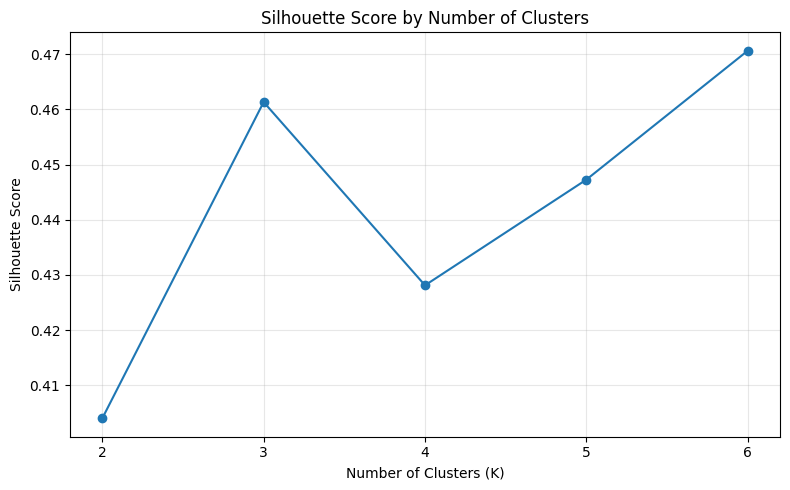

In [139]:
plt.figure(figsize=(8, 5))
plt.plot(cluster_eval["K"], cluster_eval["Silhouette Score"], marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")
plt.xticks(list(K_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 6.4 K-Means Clustering

The K value with the highest Silhouette Score is selected for the current experiment.

In [140]:
best_k = int(cluster_eval.loc[cluster_eval["Silhouette Score"].idxmax(), "K"])

final_kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["Cluster"] = final_kmeans.fit_predict(cluster_scaled)

print("Selected K:", best_k)
print("Best Silhouette Score:", cluster_eval["Silhouette Score"].max())


Selected K: 6
Best Silhouette Score: 0.47063992041625424


### 6.5 Cluster Summary

In [141]:
cluster_summary = df.groupby("Cluster").agg(
    Customers=("customerID", "count"),
    Avg_Tenure=("tenure", "mean"),
    Avg_MonthlyCharges=("MonthlyCharges", "mean"),
    Avg_TotalCharges=("TotalCharges", "mean"),
    Avg_SeniorCitizen=("SeniorCitizen", "mean"),
    Churn_Rate=("ChurnFlag", "mean")
).reset_index()

cluster_summary["Churn_Rate"] = cluster_summary["Churn_Rate"] * 100
cluster_summary = cluster_summary.sort_values("Cluster")
display(cluster_summary.round(2))


,Cluster,Customers,Avg_Tenure,Avg_MonthlyCharges,Avg_TotalCharges,Avg_SeniorCitizen,Churn_Rate
0,0,1046,53.39,33.43,1755.31,0.0,4.11
1,1,1517,59.88,92.25,5515.95,0.0,13.05
2,2,680,17.26,70.71,1118.96,1.0,53.82
3,3,1551,10.07,31.05,290.30,0.0,22.89
4,4,462,56.90,93.23,5300.13,1.0,23.81
5,5,1787,15.48,79.40,1226.98,0.0,44.60


### 6.6 Churn Rate by Cluster

After clusters are created, the churn rate is compared across clusters to understand which customer segments have higher observed churn. This is descriptive analysis, not a causal conclusion.

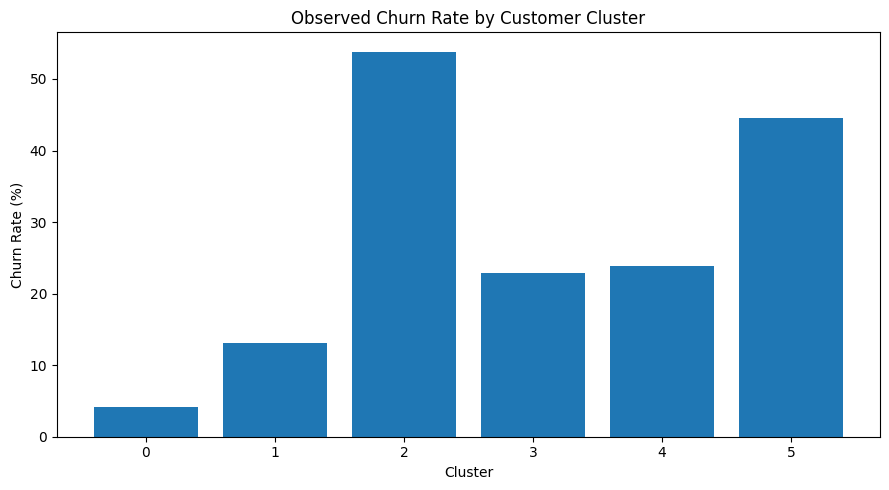

In [142]:
plt.figure(figsize=(9, 5))
plt.bar(cluster_summary["Cluster"].astype(str), cluster_summary["Churn_Rate"])
plt.xlabel("Cluster")
plt.ylabel("Churn Rate (%)")
plt.title("Observed Churn Rate by Customer Cluster")
plt.tight_layout()
plt.show()


### 6.7 Clustering Interpretation

The clusters represent customer segments based on tenure, monthly charges, total charges, and senior-citizen status. The churn rate is then used to describe how churn is distributed across these segments. The clustering result is used for customer segmentation and insight generation; it is not used as the churn prediction target.

## 7. **PREDICTIVE MINING**

### 7.1 Prepare data for predictive modeling

In [143]:
# Target
y = df["Churn"].map({"No": 0, "Yes": 1})

# Remove target and identifier
X = df.drop(
    columns=["Churn", "ChurnFlag", "customerID"],
    errors="ignore"
)

# Make sure tenure_group as categorical
if "tenure_group" in X.columns:
    X["tenure_group"] = X["tenure_group"].astype(str)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nRemaining columns:")
print(X.columns.tolist())

X shape: (7043, 21)
y shape: (7043,)

Remaining columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'tenure_group', 'Cluster']


### 7.2 Train/Test split

In [144]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training data shape: (5634, 21)
Testing data shape: (1409, 21)

Training target distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


### 7.3 Identify numerical and categorical columns


In [145]:
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Cluster']


### 7.4 Preprocessing Pipeline

In [146]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


### 7.5 Logistic Regression

In [147]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Logistic Regression pipeline created successfully.")

Logistic Regression pipeline created successfully.


#### 7.5.1 Train Logistic Regression and predict

In [148]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [149]:

y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 churn probabilities:")
print(y_prob[:10])

First 10 predictions:
[0 1 0 0 0 1 0 0 0 0]

First 10 churn probabilities:
[0.04301969 0.68303379 0.05901242 0.3297987  0.02743168 0.55479212
 0.39411488 0.11020456 0.00529076 0.3076141 ]


#### 7.5.2 Model Performance

In [150]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Logistic Regression Performance")
print("--------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Performance
--------------------------------
Accuracy : 0.8006
Precision: 0.6598
Recall   : 0.5134
F1 Score : 0.5774
ROC-AUC  : 0.8452

Confusion Matrix:
[[936  99]
 [182 192]]


### 7.6 Decision Tree

In [151]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

print("Decision Tree pipeline created successfully.")

Decision Tree pipeline created successfully.


#### 7.6.1 Decision Tree Train and Predict

In [152]:
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [153]:
y_pred_dt = decision_tree_model.predict(X_test)
y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:")
print(y_pred_dt[:10])

print("\nFirst 10 churn probabilities:")
print(y_prob_dt[:10])

First 10 predictions:
[0 1 0 1 0 0 0 0 0 1]

First 10 churn probabilities:
[0. 1. 0. 1. 0. 0. 0. 0. 0. 1.]


#### 7.6.2 Decision Tree Evaluation

In [154]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)

print("Decision Tree Performance")
print("--------------------------------")
print(f"Accuracy : {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall   : {recall_dt:.4f}")
print(f"F1 Score : {f1_dt:.4f}")
print(f"ROC-AUC  : {roc_auc_dt:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree Performance
--------------------------------
Accuracy : 0.7275
Precision: 0.4865
Recall   : 0.4813
F1 Score : 0.4839
ROC-AUC  : 0.6486

Confusion Matrix:
[[845 190]
 [194 180]]


### Logistic Regression vs Decision Tree
I found Roc-AUC is too downgrade in  Decision Tree .
In the current baseline configuration, Logistic Regression outperformed Decision Tree across Accuracy, Precision, F1-score, and ROC-AUC, while both models achieved similar Recall.

So **Logistic Regression** is currently  stronger baseline model for this dataset.

### 7.7 Random Forest

In [155]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


#### 7.7.1 Train and Predict

In [156]:
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [157]:
y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:")
print(y_pred_rf[:10])

print("\nFirst 10 churn probabilities:")
print(y_prob_rf[:10])

First 10 predictions:
[0 1 0 0 0 0 0 0 0 0]

First 10 churn probabilities:
[0.   0.78 0.05 0.32 0.01 0.32 0.39 0.09 0.03 0.4 ]


In Customer 6 : Probability = 0.42 but Prediction = 0 because setting default threshold is 0.50

#### 7.7.2 Evaluation

In [158]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Performance")
print("--------------------------------")
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1 Score : {f1_rf:.4f}")
print(f"ROC-AUC  : {roc_auc_rf:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Performance
--------------------------------
Accuracy : 0.7800
Precision: 0.6096
Recall   : 0.4759
F1 Score : 0.5345
ROC-AUC  : 0.8165

Confusion Matrix:
[[921 114]
 [196 178]]


Three  classification models were evaluated. Logistic Regression achieved the highest Accuracy, Precision, F1-score, and ROC-AUC, while Decision Tree achieved a marginally higher Recall. So, **Logistic Regression** was identified as the **strongest baseline model**

### 7.8 Class Imbalance Experiment

The target contains more `No Churn` customers than `Churn` customers. To study the effect of this imbalance, Logistic Regression is compared with and without `class_weight="balanced"`. The same train/test split is used for a fair comparison.

In [159]:
print("Class Distribution:")
print(y.value_counts())
print("\nClass Distribution (%):")
print((y.value_counts(normalize=True) * 100).round(2))


Class Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Class Distribution (%):
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [160]:
balanced_logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

balanced_logistic_model.fit(X_train, y_train)
y_pred_balanced = balanced_logistic_model.predict(X_test)
y_prob_balanced = balanced_logistic_model.predict_proba(X_test)[:, 1]

accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
precision_balanced = precision_score(y_test, y_pred_balanced)
recall_balanced = recall_score(y_test, y_pred_balanced)
f1_balanced = f1_score(y_test, y_pred_balanced)
roc_auc_balanced = roc_auc_score(y_test, y_prob_balanced)

baseline_metrics = {
    "Model": "Logistic Regression - No Scaling",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "ROC-AUC": roc_auc
}

balanced_metrics = {
    "Model": "Logistic Regression - Balanced",
    "Accuracy": accuracy_balanced,
    "Precision": precision_balanced,
    "Recall": recall_balanced,
    "F1 Score": f1_balanced,
    "ROC-AUC": roc_auc_balanced
}

imbalance_results = pd.DataFrame([baseline_metrics, balanced_metrics])
display(imbalance_results.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression - No Scaling,0.8006,0.6598,0.5134,0.5774,0.8452
1,Logistic Regression - Balanced,0.7374,0.5034,0.7968,0.6170,0.8451


Baseline Logistic Regression Confusion Matrix
[[936  99]
 [182 192]]

Balanced Logistic Regression Confusion Matrix
[[741 294]
 [ 76 298]]


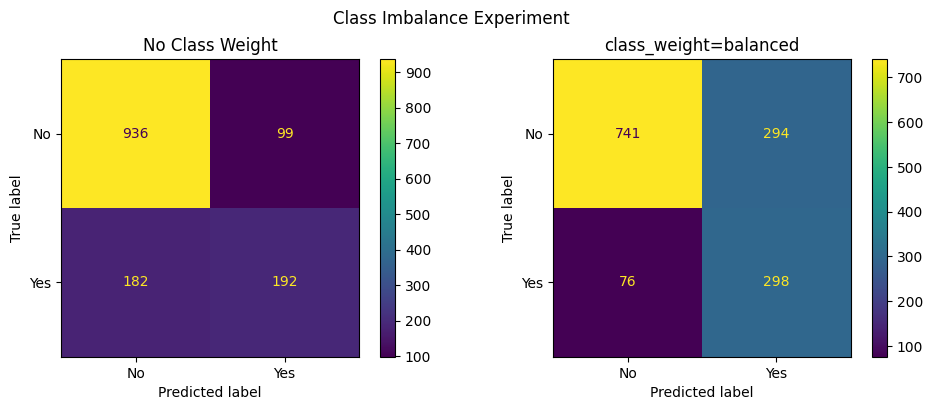

In [161]:
from sklearn.metrics import ConfusionMatrixDisplay

print("Baseline Logistic Regression Confusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("\nBalanced Logistic Regression Confusion Matrix")
print(confusion_matrix(y_test, y_pred_balanced))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, y_pred),
    display_labels=["No", "Yes"]
).plot(ax=axes[0], values_format="d")
axes[0].set_title("No Class Weight")

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, y_pred_balanced),
    display_labels=["No", "Yes"]
).plot(ax=axes[1], values_format="d")
axes[1].set_title("class_weight=balanced")

plt.suptitle("Class Imbalance Experiment")
plt.tight_layout()
plt.show()


**Interpretation:** Using `class_weight="balanced"` gives more importance to the minority churn class. In the experiment, this increases Recall but also increases False Positives, so Accuracy and Precision may decrease. The choice should therefore consider the business cost of missing churners versus contacting customers who may not churn.

### 7.9 SMOTE Experiment

SMOTE (Synthetic Minority Over-sampling Technique) is applied to the training data to create synthetic samples for the minority `Churn` class. The test data is kept unchanged for a fair evaluation.


In [162]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

# Use a dense output for SMOTE because SMOTE operates on numeric arrays.
smote_numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

smote_categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

smote_preprocessor = ColumnTransformer(
    transformers=[
        ("num", smote_numeric_transformer, numerical_cols),
        ("cat", smote_categorical_transformer, categorical_cols)
    ]
)

smote_logistic_model = ImbPipeline(steps=[
    ("preprocessor", smote_preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("SMOTE Logistic Regression pipeline created successfully.")


SMOTE Logistic Regression pipeline created successfully.


In [163]:
smote_logistic_model.fit(X_train, y_train)

y_pred_smote = smote_logistic_model.predict(X_test)
y_prob_smote = smote_logistic_model.predict_proba(X_test)[:, 1]

accuracy_smote = accuracy_score(y_test, y_pred_smote)
precision_smote = precision_score(y_test, y_pred_smote)
recall_smote = recall_score(y_test, y_pred_smote)
f1_smote = f1_score(y_test, y_pred_smote)
roc_auc_smote = roc_auc_score(y_test, y_prob_smote)

smote_metrics = {
    "Model": "Logistic Regression - SMOTE",
    "Accuracy": accuracy_smote,
    "Precision": precision_smote,
    "Recall": recall_smote,
    "F1 Score": f1_smote,
    "ROC-AUC": roc_auc_smote
}

imbalance_smote_results = pd.DataFrame([
    baseline_metrics,
    balanced_metrics,
    smote_metrics
])

display(imbalance_smote_results.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression - No Scaling,0.8006,0.6598,0.5134,0.5774,0.8452
1,Logistic Regression - Balanced,0.7374,0.5034,0.7968,0.6170,0.8451
2,Logistic Regression - SMOTE,0.7459,0.5138,0.7941,0.6239,0.8428


SMOTE Logistic Regression Confusion Matrix
[[754 281]
 [ 77 297]]


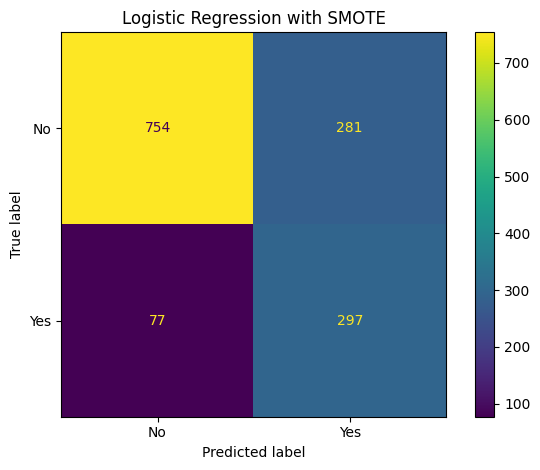

In [164]:
print("SMOTE Logistic Regression Confusion Matrix")
print(confusion_matrix(y_test, y_pred_smote))

cm_smote = confusion_matrix(y_test, y_pred_smote)

ConfusionMatrixDisplay(
    confusion_matrix=cm_smote,
    display_labels=["No", "Yes"]
).plot(values_format="d")
plt.title("Logistic Regression with SMOTE")
plt.tight_layout()
plt.show()


**SMOTE Interpretation:** SMOTE creates synthetic samples for the minority `Churn` class only in the training data. The test set remains unchanged. In this experiment, SMOTE achieved Recall of 79.41% and F1-score of 61.94%, while Accuracy was 74.10%, Precision was 50.77%, and ROC-AUC was 84.28%. The result shows a trade-off similar to class weighting: higher Recall is obtained at the cost of lower Precision and Accuracy compared with the baseline.


### 8. Visualization

#### 8.1 Confusion Matrix Visualize

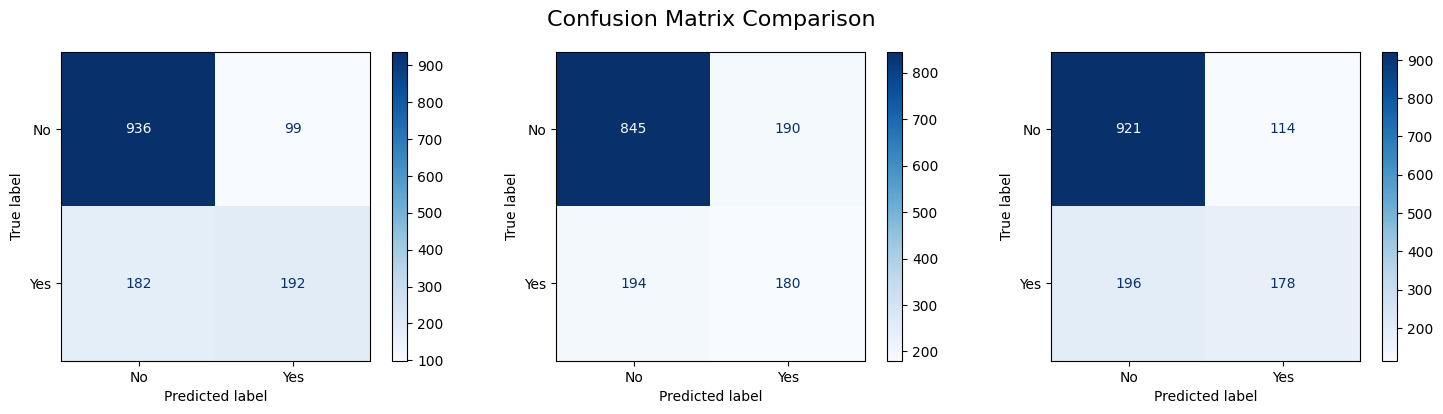

In [165]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion matrices
cm_lr = confusion_matrix(y_test, y_pred)
cm_dt = confusion_matrix(y_test, y_pred_dt)
cm_rf = confusion_matrix(y_test, y_pred_rf)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cmap = "Blues"

# Logistic Regression
ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["No", "Yes"]
).plot(ax=axes[0], values_format="d", cmap=cmap)

# Decision Tree
ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["No", "Yes"]
).plot(ax=axes[1], values_format="d", cmap=cmap)

# Random Forest
ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No", "Yes"]
).plot(ax=axes[2], values_format="d", cmap=cmap)

plt.suptitle("Confusion Matrix Comparison", fontsize=16)
plt.tight_layout()
plt.show()

#### 8.2 Performance Chart

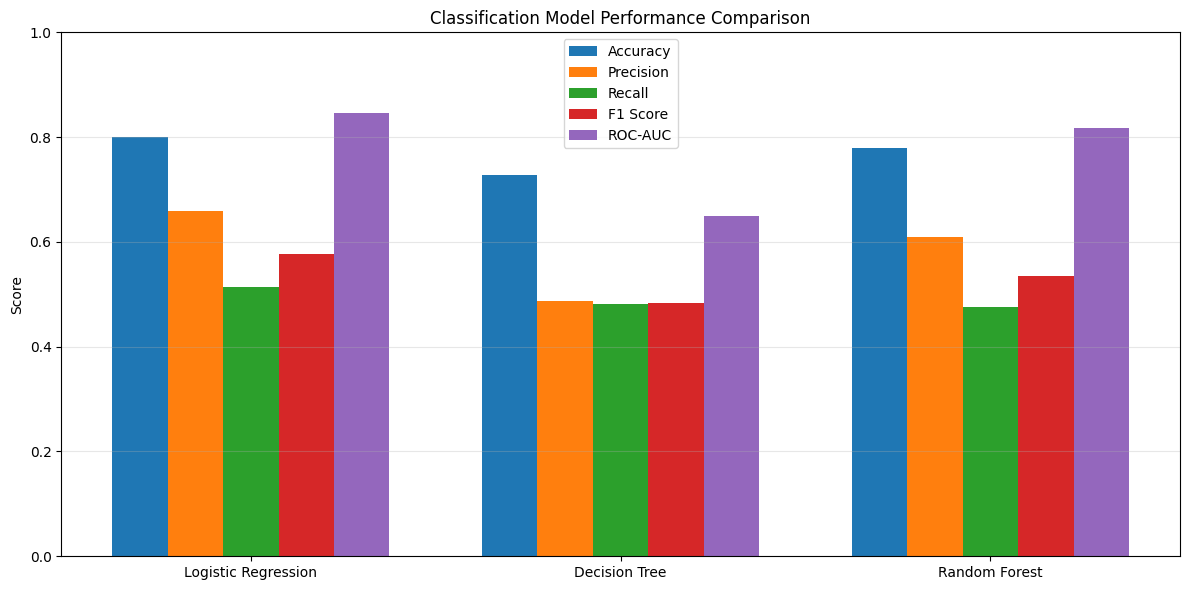

In [166]:
import numpy as np
import matplotlib.pyplot as plt

models = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

accuracy_scores = [accuracy, accuracy_dt, accuracy_rf]
precision_scores = [precision, precision_dt, precision_rf]
recall_scores = [recall, recall_dt, recall_rf]
f1_scores = [f1, f1_dt, f1_rf]
roc_auc_scores = [roc_auc, roc_auc_dt, roc_auc_rf]

x = np.arange(len(models))
width = 0.15

plt.figure(figsize=(12, 6))

plt.bar(x - 2*width, accuracy_scores, width, label="Accuracy")
plt.bar(x - width, precision_scores, width, label="Precision")
plt.bar(x, recall_scores, width, label="Recall")
plt.bar(x + width, f1_scores, width, label="F1 Score")
plt.bar(x + 2*width, roc_auc_scores, width, label="ROC-AUC")

plt.xticks(x, models)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Classification Model Performance Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### 8.3 ROC Curve

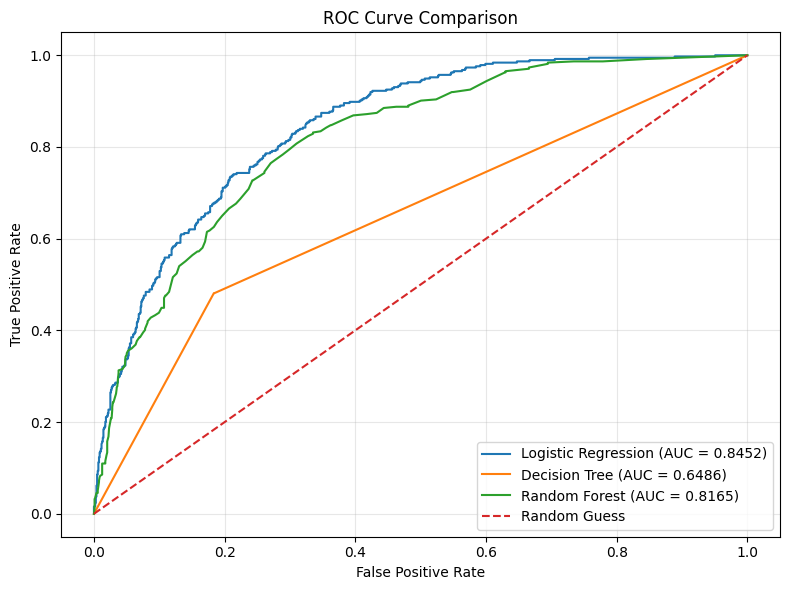

In [167]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Calculate ROC curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {roc_auc:.4f})"
)

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f"Decision Tree (AUC = {roc_auc_dt:.4f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {roc_auc_rf:.4f})"
)

# Random guessing line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guess"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Model Comparison Chart

#### Final Model Selection:
Based on the baseline evaluation results, Logistic Regression was selected as the final model because of the highest Accuracy (80.13%), Precision (66.10%), F1-score (57.96%), and ROC-AUC (84.49%) . Although Decision Tree achieved a slightly higher Recall (51.87%) than Logistic Regression (51.60%), the difference was small. So, Logistic Regression provided the strongest overall baseline performance for customer churn prediction

### 9. Model Interpretation

In [168]:
# Get feature names after preprocessing
feature_names = logistic_model.named_steps["preprocessor"].get_feature_names_out()

coefficients = logistic_model.named_steps["classifier"].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by coefficient
feature_importance = feature_importance.sort_values(
    by="Coefficient",
    ascending=False
)

feature_importance.head(15)

,Feature,Coefficient
17,cat__InternetService_Fiber optic,0.695771
37,cat__Contract_Month-to-month,0.651424
46,cat__tenure_group_0-6,0.419415
36,cat__StreamingMovies_Yes,0.244072
33,cat__StreamingTV_Yes,0.239278
44,cat__PaymentMethod_Electronic check,0.188312
15,cat__MultipleLines_Yes,0.156937
19,cat__OnlineSecurity_No,0.145553
28,cat__TechSupport_No,0.120632
27,cat__DeviceProtection_Yes,0.059078


The model assigns a relatively strong positive coefficient to Fiber optic service, indicating that this feature contributes toward a higher predicted churn tendency, after accounting for the other features in the model

## 10. Dashboard

In [169]:
# save Logistic Regression Model

import joblib

joblib.dump(logistic_model, "logistic_regression_model.pkl")

print("Model saved successfully!")

Model saved successfully!
